# Etapa 4 — Análise de Correlação e Regressão

**Objetivo:** quantificar a relação entre `valor_contratado` e as features construídas
na camada gold (Etapa 3); interpretar modelos de regressão linear (simples, múltipla); avaliar o ajuste com R², RMSE e MAE em **validação temporal**.

- correlação (Pearson e Spearman) e matriz de correlação;
- regressão linear: mínimos quadrados, coeficientes, R²;
- regressão linear múltipla;

In [103]:
# =============================================================
# 1. SETUP, PALETA E CARREGAMENTO DA GOLD
# =============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import statsmodels.api as sm

# Paleta 
paleta_cores = {"azul": "#003B5C", "laranja": "#F15A22", "cinza": "#D9D9D9", "verde": "#00A99D"}
PALETA = list(paleta_cores.values())

sns.set_theme(style="whitegrid", context="notebook", palette=list(paleta_cores.values()), font_scale=1.1)

plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

RANDOM_STATE = 42
TARGET       = "valor_contratado"  # valor operacao no projeto
PATH_GOLD    = "../data/gold/bnds_features.parquet"

df = pd.read_parquet(PATH_GOLD)
df["data_contratacao"] = pd.to_datetime(df["data_contratacao"])

print(f"Gold carregada: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print(f"Período: {df['data_contratacao'].min().date()} a {df['data_contratacao'].max().date()}")

Gold carregada: 8,294 linhas × 144 colunas
Período: 2002-01-02 a 2026-04-30


## 1. Split temporal treino / teste

Como o problema é de negócio e os dados têm ordem temporal, **não usamos split
aleatório**. Treinamos em anos anteriores e testamos no período mais recente.

- **Treino:** tudo até o ano de corte.
- **Teste:** a partir do ano de corte.

In [104]:
# =============================================================
# 2. SPLIT TEMPORAL
# =============================================================
ANO_CORTE = int(df["ano_contratacao"].quantile(0.80))   # ~80/20 temporal

mask_treino = df["ano_contratacao"] < ANO_CORTE
mask_teste  = df["ano_contratacao"] >= ANO_CORTE

treino = df.loc[mask_treino].copy()
teste  = df.loc[mask_teste].copy()

print(f"Ano de corte: {ANO_CORTE}")
print(f"Treino: {len(treino):>6,} linhas | anos {treino['ano_contratacao'].min()}–{treino['ano_contratacao'].max()}")
print(f"Teste : {len(teste):>6,} linhas | anos {teste['ano_contratacao'].min()}–{teste['ano_contratacao'].max()}")

Ano de corte: 2018
Treino:  6,479 linhas | anos 2002–2017
Teste :  1,815 linhas | anos 2018–2026


In [105]:
# =============================================================
# 3. MATRIZES X / y (features numéricas já codificadas na gold)
# =============================================================
# Colunas que NÃO entram como features
COLS_CONTROLE = ["data_contratacao", TARGET]

features = [c for c in treino.columns
            if c not in COLS_CONTROLE
            and pd.api.types.is_numeric_dtype(treino[c])]

X_train, y_train = treino[features].copy(), treino[TARGET].copy()
X_test,  y_test  = teste[features].copy(),  teste[TARGET].copy()

# Alvo transformado — reduz assimetria e alinha com pressupostos da regressão
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

print(f"Nº de features: {len(features)}")
# Assimetrias do alvo (skewness)
print(f"Assimetria do alvo — treino bruto: {y_train.skew():.2f} | log: {y_train_log.skew():.2f}")

Nº de features: 141
Assimetria do alvo — treino bruto: 20.96 | log: -0.23


- Transformação Logarítmica do Alvo: o resultado mostra a assimetria (skewness) do valor_contratado bruto era de 28,96 (altamente distorcida por contratos bilionários). Ao aplicar log1p, a assimetria caiu para -0,23 (quase perfeitamente simétrica). Isso é essencial para que a Regressão Linear funcione corretamente.

## 2. Correlação

- **Pearson:** correlação linear. Sensível a outliers e pressupõe normalidade
  bivariada — o que **não** é o caso aqui. (mantemos apenas para comparação)
- **Spearman:** correlação de postos (monotônica). Robusta a outliers e
  não exige normalidade — **é a nossa métrica principal** para o alvo.

Calculamos ambas com o alvo no conjunto de **treino** para
respeitar o split temporal.

In [106]:
# =============================================================
# 4. CORRELAÇÃO COM O ALVO (TREINO)
# =============================================================
def correlacoes_com_alvo(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """Retorna Pearson e Spearman de cada feature com o alvo."""
    base = X.copy()
    base[TARGET] = y.values
    pearson  = base.corr(method="pearson")[TARGET].drop(TARGET)
    spearman = base.corr(method="spearman")[TARGET].drop(TARGET)
    return pd.DataFrame({
        "pearson":  pearson.round(3),
        "spearman": spearman.round(3),
    }).assign(abs_spearman=lambda d: d["spearman"].abs())

corr_treino = correlacoes_com_alvo(X_train, y_train_log)
top_spearman = corr_treino.sort_values("abs_spearman", ascending=False).head(15)

print("=== Top 15 correlações (Spearman) com log1p(valor_contratado) — treino ===")
top_spearman

=== Top 15 correlações (Spearman) com log1p(valor_contratado) — treino ===


,pearson,spearman,abs_spearman
porte_hist_volume,0.35,0.45,0.45
porte_hist_ticket_medio,0.45,0.44,0.44
flag_micro_pequena,-0.45,-0.43,0.43
flag_reembolsavel,0.45,0.43,0.43
modalidade_apoio_NAO REEMBOLSAVEL,-0.45,-0.43,0.43
produto_BNDES NAO REEMBOLSAVEL,-0.45,-0.43,0.43
modalidade_apoio_REEMBOLSAVEL,0.45,0.43,0.43
tipo_garantia_NAO SE APLICA,-0.45,-0.42,0.42
custo_financeiro_SEM CUSTO,-0.45,-0.42,0.42
setor_hist_ticket_medio,0.40,0.42,0.42


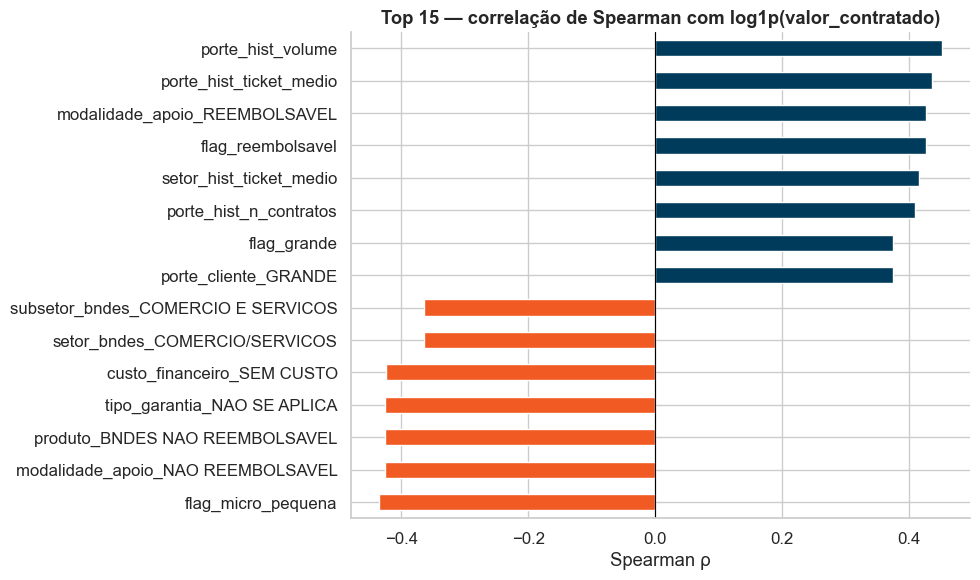

In [107]:
# =============================================================
# 5. TOP 15 CORRELAÇÕES — BARRAS HORIZONTAIS
# =============================================================
fig, ax = plt.subplots(figsize=(10, 6))
plot = top_spearman["spearman"].sort_values()
cores = [paleta_cores["laranja"] if v < 0 else paleta_cores["azul"] for v in plot]
plot.plot.barh(ax=ax, color=cores)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 — correlação de Spearman com log1p(valor_contratado)")
ax.set_xlabel("Spearman ρ")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 3. Matriz de correlação

A matriz completa tem muitas colunas após o one-hot — visualizá-la inteira é
ilegível.

1. Selecionar as **20 features mais correlacionadas com o alvo** (Spearman).
2. Plotar a matriz **Spearman** desse subconjunto + o alvo.

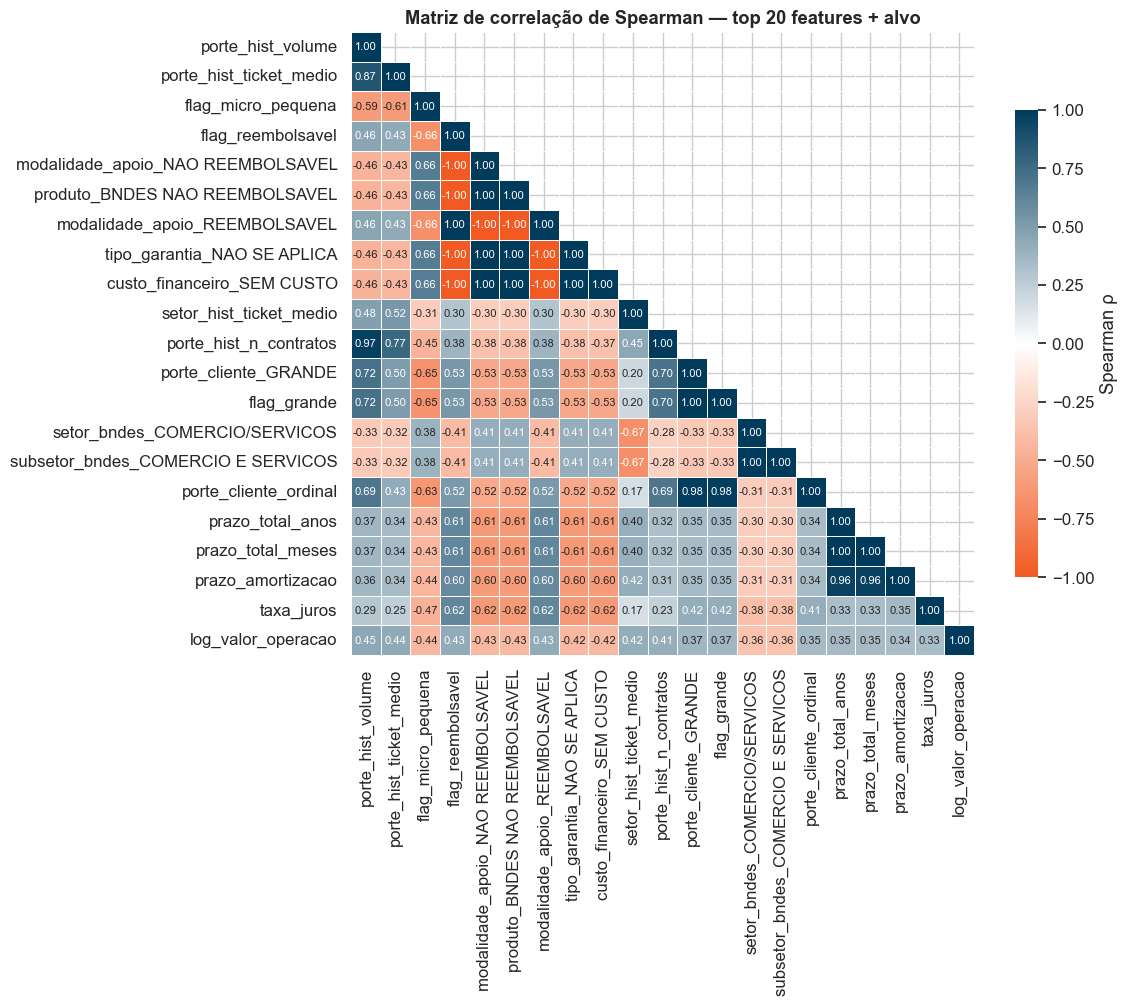

In [108]:
# =============================================================
# 6. MATRIZ DE CORRELAÇÃO (SUBCONJUNTO)
# =============================================================
TOP_N_MATRIZ = 20
top_features = corr_treino["abs_spearman"].sort_values(ascending=False).head(TOP_N_MATRIZ).index.tolist()

base_matriz = X_train[top_features].copy()
base_matriz["log_valor_operacao"] = y_train_log.values

matriz_corr = base_matriz.corr(method="spearman")

# Máscara triangular (evita redundância visual)
mask = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)

# Paleta divergente ancorada nas cores institucionais
from matplotlib.colors import LinearSegmentedColormap
cmap_div = LinearSegmentedColormap.from_list(
    "institucional",
    [paleta_cores["laranja"], "#FFFFFF", paleta_cores["azul"]]
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    matriz_corr, mask=mask, cmap=cmap_div, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    linewidths=0.5, linecolor="white", square=True, ax=ax,
    cbar_kws={"shrink": 0.75, "label": "Spearman ρ"},
)
ax.set_title(f"Matriz de correlação de Spearman — top {TOP_N_MATRIZ} features + alvo")
plt.tight_layout()
plt.show()

### Dispersão dos 3 melhores preditores vs alvo

Complementamos a matriz com o **scatter** dos três maiores Spearman vs
`log1p(valor_contratado)`, adicionando uma **reta de regressão local (LOWESS)**
para enxergar a forma da relação — se linear, monotônica não linear ou em U.

c:\Users\AndreFelipeCiccoRiba\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


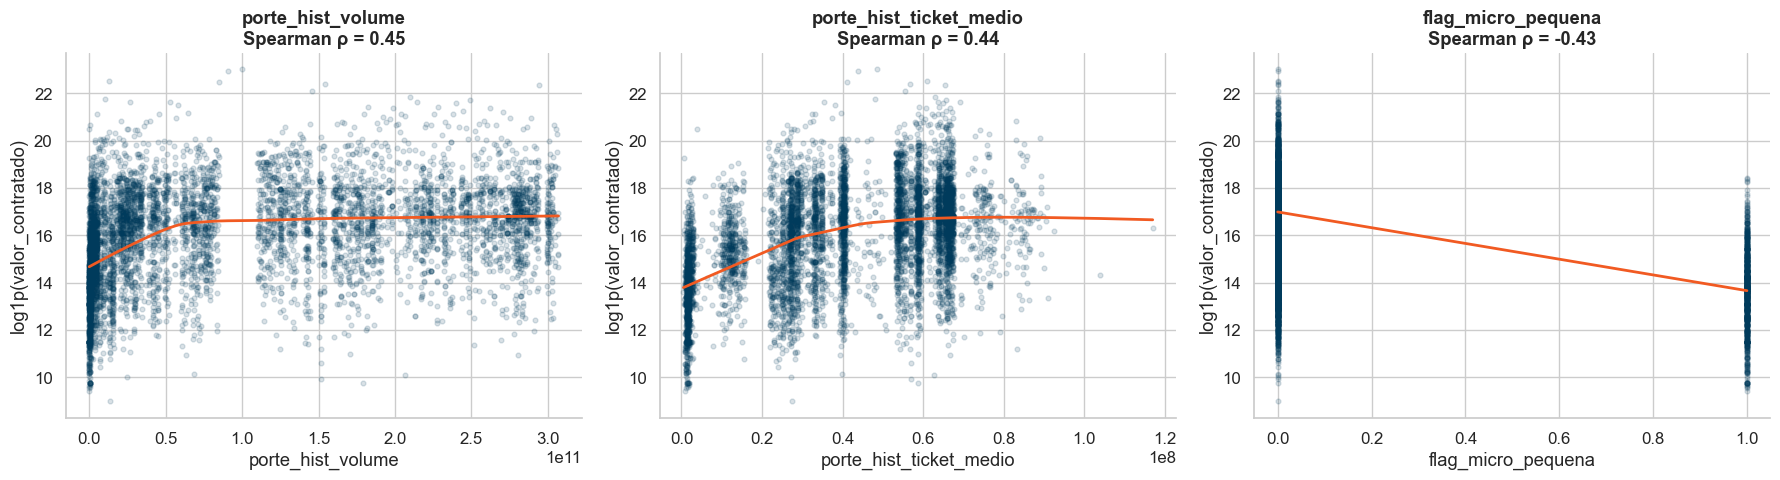

In [109]:
# =============================================================
# 7. DISPERSÃO DOS TOP 3 PREDITORES vs ALVO
# =============================================================
top3 = corr_treino["abs_spearman"].sort_values(ascending=False).head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, top3):
    sns.regplot(
        x=X_train[feat], y=y_train_log,
        ax=ax, scatter_kws={"alpha": 0.15, "s": 12, "color": paleta_cores["azul"]},
        line_kws={"color": paleta_cores["laranja"], "linewidth": 2},
        lowess=True,
    )
    rho = corr_treino.loc[feat, "spearman"]
    ax.set_title(f"{feat}\nSpearman ρ = {rho:.2f}")
    ax.set_xlabel(feat)
    ax.set_ylabel("log1p(valor_contratado)")

plt.tight_layout()
plt.show()

- A análise de correlação validou empiricamente a hipótese de negócio de que o porte da empresa e o histórico de contratações são os principais vetores para determinar o tamanho do novo contrato. A transformação logarítmica do alvo mostrou-se indispensável para reduzir a assimetria provocada por outliers (contratos bilionários). No entanto, a matriz de correlação acendeu um alerta metodológico: a presença de multicolinearidade severa (ρ = 0.99) entre as variáveis históricas de volume e ticket médio. Para a próxima etapa (Modelagem Preditiva), será necessário aplicar técnicas de regularização (como Ridge ou Lasso) ou seleção de features para garantir que o modelo de regressão seja estável e interpretável.

## 4. Regressão linear simples — mínimos quadrados

O método dos **mínimos quadrados ordinários (OLS)** estima os coeficientes
que minimizam a soma dos quadrados dos resíduos. Aqui: um modelo com o
**melhor preditor único** 

Interpretação:
- **Coeficiente:** variação esperada em `log1p(valor_operacao)` para +1 unidade
  da feature.
- **R²:** proporção da variância do alvo explicada pelo modelo (0 a 1).
- **RMSE / MAE:** erro típico — quanto menor, melhor.

In [110]:
# =============================================================
# 8. REGRESSÃO LINEAR SIMPLES (statsmodels → tabela interpretável)
# =============================================================
melhor_feat = top3[0]

X_simple_train = sm.add_constant(X_train[[melhor_feat]])
X_simple_test  = sm.add_constant(X_test[[melhor_feat]])

modelo_simples = sm.OLS(y_train_log, X_simple_train).fit()

print(f"=== OLS: log1p(valor_contratado) ~ {melhor_feat} ===")
print(modelo_simples.summary().tables[1])

# Predições no teste
pred_simples = modelo_simples.predict(X_simple_test)

# Métricas no teste (em escala log)
r2_simples   = r2_score(y_test_log, pred_simples)
rmse_simples = np.sqrt(mean_squared_error(y_test_log, pred_simples))
mae_simples  = mean_absolute_error(y_test_log, pred_simples)

print(f"\nAvaliação no TESTE (escala log):")
print(f"  R²   = {r2_simples:.4f}")
print(f"  RMSE = {rmse_simples:.4f}")
print(f"  MAE  = {mae_simples:.4f}")

=== OLS: log1p(valor_contratado) ~ porte_hist_volume ===
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                15.2360      0.033    463.861      0.000      15.172      15.300
porte_hist_volume  7.089e-12   2.36e-13     29.995      0.000    6.63e-12    7.55e-12

Avaliação no TESTE (escala log):
  R²   = -0.0738
  RMSE = 1.9981
  MAE  = 1.5199


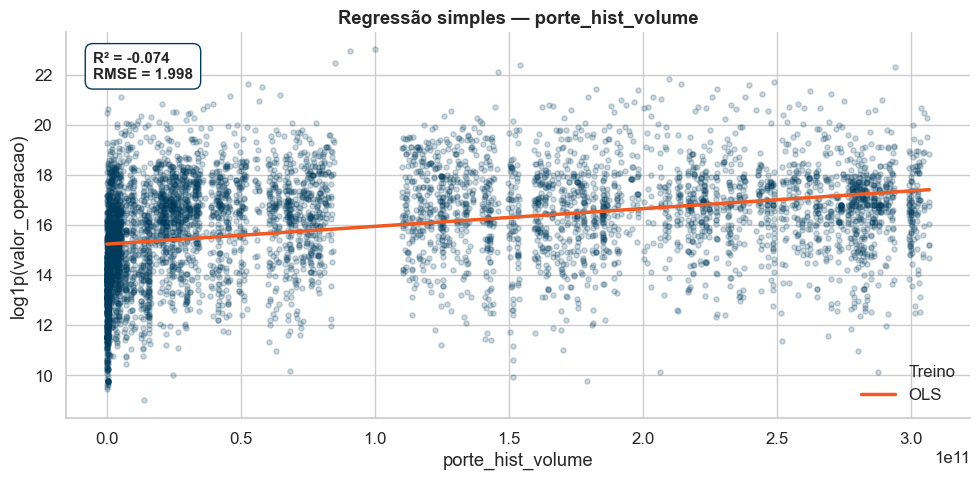

In [111]:
# =============================================================
# 9. GRÁFICO DA REGRESSÃO COM R² ANOTADO
# =============================================================
fig, ax = plt.subplots(figsize=(10, 5))

# Pontos de treino
ax.scatter(X_train[melhor_feat], y_train_log,
           s=14, alpha=0.20, color=paleta_cores["azul"], label="Treino")

# Reta de regressão
xs = np.linspace(X_train[melhor_feat].min(), X_train[melhor_feat].max(), 200)
ys = modelo_simples.params.iloc[0] + modelo_simples.params.iloc[1] * xs
ax.plot(xs, ys, color=paleta_cores["laranja"], linewidth=2.5, label="OLS")

# Anotação do R²
ax.text(
    0.03, 0.95,
    f"R² = {r2_simples:.3f}\nRMSE = {rmse_simples:.3f}",
    transform=ax.transAxes, va="top",
    fontsize=11, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.5",
              facecolor="white", edgecolor=paleta_cores["azul"]),
)

ax.set_title(f"Regressão simples — {melhor_feat}")
ax.set_xlabel(melhor_feat)
ax.set_ylabel("log1p(valor_operacao)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### Entendendo o resultado: 
O R deve variar entre 0 a 1. O resultado de (R = -0.074) indica que o sozinho "porte_hist_volume" não explica nada sobre o valor_contratado. Ou seja, significa que o modelo é pior do que simplesmente "chutar" a média de todos os contratos.

A análise visual do dispersograma (scatter plot) revela a causa raiz:
1. **Dispersão Vertical (Underfitting):** O gráfico forma "degraus" verticais, mostrando que para um mesmo patamar de histórico de volume, o alvo `log1p(valor_contratado)` varia de 10 a 22. Uma única variável é matematicamente insuficiente para capturar essa complexidade.
2. **Deriva Temporal (Concept Drift):** Como o modelo foi treinado no passado (até 2017) e testado no futuro (2018+), a reta OLS ajustada não se generalizou. O ciclo econômico recente pode ter mudado a dinâmica de concessão de crédito.
3. **Não-Linearidade:** A relação entre o histórico acumulado (que cresce exponencialmente) e o novo contrato não é uma reta. 

**Conclusão da Etapa:** A Regressão Simples serviu ao seu propósito acadêmico de provar que o tamanho do contrato do BNDES é um fenômeno multivariado. É necessária a transição imediata para a **Regressão Múltipla**, incluindo variáveis de porte, taxa de juros, setores e prazos para tentar capturar a variância.

## 5. Regressão linear múltipla

Com todas as features preparadas na gold, estimamos o modelo múltiplo.
Aqui a interpretação individual dos coeficientes fica **comprometida pela
multicolinearidade** (comum em bases com one-hot e históricos). Por isso:

- Para **interpretação:** usamos `statsmodels` com as **15 features mais
  correlacionadas** (menos ruído, menos colinearidade).
- Para **desempenho:** usamos `sklearn` com **todas as features** (reportamos
  R², RMSE e MAE no teste).

In [112]:
# =============================================================
# 10. REGRESSÃO MÚLTIPLA — INTERPRETÁVEL (top 15 features)
# =============================================================
top15 = corr_treino["abs_spearman"].sort_values(ascending=False).head(15).index.tolist()

X_mult_train_sm = sm.add_constant(X_train[top15])
modelo_mult_sm  = sm.OLS(y_train_log, X_mult_train_sm).fit()

print("=== OLS múltiplo (top 15) — coeficientes ===")
print(modelo_mult_sm.summary().tables[1])

# Diagnóstico rápido de multicolinearidade via VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame({
    "feature": X_mult_train_sm.columns,
    "VIF": [variance_inflation_factor(X_mult_train_sm.values, i)
            for i in range(X_mult_train_sm.shape[1])],
}).query("feature != 'const'").sort_values("VIF", ascending=False)

print("\n=== VIF (multicolinearidade) — top 10 ===")
print(vif.head(10).round(2))

=== OLS múltiplo (top 15) — coeficientes ===
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                  5.8571      0.421     13.923      0.000       5.032       6.682
porte_hist_volume                  -2.179e-11   1.71e-12    -12.724      0.000   -2.51e-11   -1.84e-11
porte_hist_ticket_medio             1.477e-08   1.91e-09      7.746      0.000     1.1e-08    1.85e-08
flag_micro_pequena                    -0.7915      0.109     -7.272      0.000      -1.005      -0.578
flag_reembolsavel                      4.4902      0.211     21.292      0.000       4.077       4.904
modalidade_apoio_NAO REEMBOLSAVEL      1.3669      0.627      2.180      0.029       0.137       2.596
produto_BNDES NAO REEMBOLSAVEL         1.3669      0.627      2.180      0.029       0.137       2.596
modalidade_apoio_REEMBOLSAVE

c:\Users\AndreFelipeCiccoRiba\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
c:\Users\AndreFelipeCiccoRiba\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


- Análise dos coeficientes e teste VIF revela instabilidade (efeito da multicolinearidade estrutural das dummies).

In [125]:
# =============================================================
# 11. REGRESSÃO MÚLTIPLA — DESEMPENHO (sklearn, todas as features)
# =============================================================
modelo_mult = LinearRegression()
modelo_mult.fit(X_train, y_train_log)

pred_mult = modelo_mult.predict(X_test)

r2_mult   = r2_score(y_test_log, pred_mult)
rmse_mult = np.sqrt(mean_squared_error(y_test_log, pred_mult))
mae_mult  = mean_absolute_error(y_test_log, pred_mult)

print("Avaliação no TESTE (escala log):")
print(f"  R²   = {r2_mult:.4f}")
print(f"  RMSE = {rmse_mult:.4f}")
print(f"  MAE  = {mae_mult:.4f}")

Avaliação no TESTE (escala log):
  R²   = -0.0052
  RMSE = 1.9332
  MAE  = 1.5046


1. **Multicolinearidade Perfeita (VIF = inf):** A base possui redundância matemática. Variáveis como `flag_reembolsavel` e `modalidade_apoio_REEMBOLSAVEL` são idênticas. Isso está impossibilitando a interpretação dos coeficientes e gerando estimativas instáveis (como o coeficiente negativo da variável `porte_hist_volume`).
   
**Decisão Metodológica:** O modelo OLS tradicional provou-se inadequado para esta base. Para a próxima etapa, além de remover as features redundantes (limpeza de dummies), iremos testar o uso de **modelos regularizados (Ridge/Lasso)** e **modelos baseados em árvores (Random Forest/XGBoost)**, que são imunes à multicolinearidade e capturam as relações não-lineares dos dados.